Shape: (10000, 14)
   RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               1   

   EstimatedSalary  Exited  
0        101348.88       1  
1        112542.58       0  
2        113931.57       1  
3         93826.63     

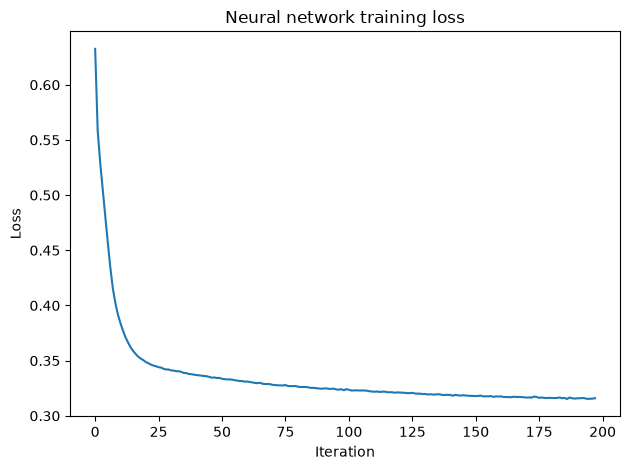

Best parameters: {'model__alpha': 0.0001, 'model__hidden_layer_sizes': (8,)}
Optimized accuracy: 0.8635
Confusion matrix:
 [[1537   56]
 [ 217  190]]
              precision    recall  f1-score   support

           0       0.88      0.96      0.92      1593
           1       0.77      0.47      0.58       407

    accuracy                           0.86      2000
   macro avg       0.82      0.72      0.75      2000
weighted avg       0.86      0.86      0.85      2000



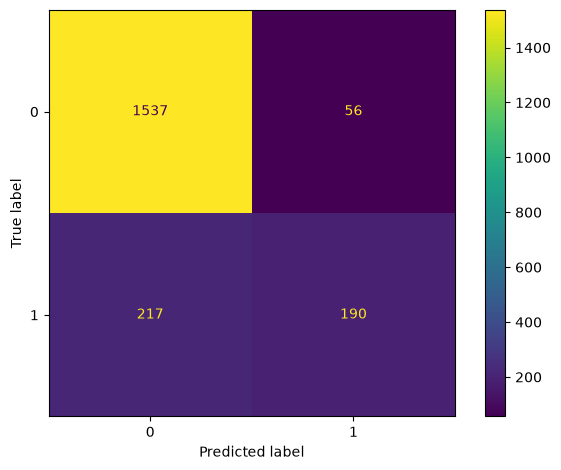

In [1]:
"""B3: Bank customer churn prediction using a neural network."""
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

DATA_URL = "https://raw.githubusercontent.com/sharmaroshan/Churn-Modelling-Dataset/master/Churn_Modelling.csv"
df = pd.read_csv(DATA_URL)

print("Shape:", df.shape)
print(df.head())
print("Missing values:\n", df.isnull().sum())
print("Churn distribution:\n", df["Exited"].value_counts())

df = df.drop(columns=["RowNumber", "CustomerId", "Surname"], errors="ignore")
X = df.drop(columns=["Exited"])
y = df["Exited"]

categorical = ["Geography", "Gender"]
numeric = [col for col in X.columns if col not in categorical]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Preprocessing is inside the pipeline, preventing test-data leakage.
pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", MLPClassifier(
        hidden_layer_sizes=(16, 8), activation="relu",
        max_iter=300, random_state=42
    )),
])

pipeline.fit(X_train, y_train)
basic_predictions = pipeline.predict(X_test)
print("\nBasic neural network accuracy:",
      accuracy_score(y_test, basic_predictions))

loss_values = pipeline.named_steps["model"].loss_curve_
plt.plot(loss_values)
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Neural network training loss")
plt.tight_layout()
plt.show()

# Grid search selects model settings using training data only.
parameters = {
    "model__hidden_layer_sizes": [(8,), (16, 8), (32, 16)],
    "model__alpha": [0.0001, 0.001],
}
grid = GridSearchCV(pipeline, parameters, cv=3, scoring="accuracy", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
best_model = grid.best_estimator_
predictions = best_model.predict(X_test)

cm = confusion_matrix(y_test, predictions)
print("Optimized accuracy:", accuracy_score(y_test, predictions))
print("Confusion matrix:\n", cm)
print(classification_report(y_test, predictions, zero_division=0))
ConfusionMatrixDisplay(confusion_matrix=cm).plot()
plt.tight_layout()
plt.show()
